<a href="https://colab.research.google.com/github/BaDoingleZoinks/TXST-TECH4397-WaterQuality-ML/blob/main/notebooks/Copy_of_Assignment_6_Starter_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TECH 4397: Assignment 6 — Can We Rescue the DO Sensor?
### Guided Computational Experiment (No Prior Coding Required!)

**Welcome!** You do **not** need to write Python code from scratch for this assignment. Every step is already written for you.

**How to use this notebook:**
1. Click **File -> Save a copy in Drive** at the top left so you have your own personal copy.
2. To run a gray code box (called a **Cell**), click the **Play button (▶)** on the left side of the box (or press `Shift + Enter`).
3. Run the cells in order from **Step 1** down to **Step 5**.
4. You will only need to change **a few numbers or words** where clearly marked with `# <--- CHANGE THIS`.

---
## STEP 1: Load the Musunooru Dataset ($n=79$)
**Action:** Click the **Play button (▶)** on the cell below to load the 79 laboratory water-quality samples and set up our helper tools.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.svm import SVC, SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import accuracy_score, f1_score, r2_score, mean_squared_error

# Create the 79-sample laboratory dataset from Musunooru's thesis
np.random.seed(42)
chems = (
    ['Sodium Bicarbonate'] * 21 +
    ['Calcium Carbonate'] * 17 +
    ['Sodium Chloride'] * 16 +
    ['Hydrogen Peroxide'] * 14 +
    ['Magnesium'] * 11
)

doses = np.concatenate([
    np.linspace(0.01, 0.60, 21),   # NaHCO3 (g)
    np.linspace(0.01, 0.40, 17),   # CaCO3 (g)
    np.linspace(0.01, 0.225, 16),  # NaCl (g)
    np.linspace(1.0, 26.0, 14),    # H2O2 (mL)
    np.linspace(0.005, 0.10, 11)   # Mg (g)
])

# Sensor voltage responses matching thesis Tables 3-1, 4-1, and 7-2
pH_nahco3   = 2.40 + 0.35 * (doses[:21] / 0.60) + np.random.normal(0, 0.004, 21)
tds_nahco3  = 0.015 + 0.24 * (doses[:21] / 0.60) + np.random.normal(0, 0.002, 21)
do_nahco3   = 0.265 + 0.030 * (doses[:21] / 0.60) + np.random.normal(0, 0.002, 21)
turb_nahco3 = 0.0025 + 0.045 * (doses[:21] / 0.60) + np.abs(np.random.normal(0, 0.0005, 21))

d_caco3 = doses[21:38]
pH_caco3   = 2.34 - 0.12 * (d_caco3 / 0.40) + np.random.normal(0, 0.004, 17)
tds_caco3  = 0.008 + 0.042 * (d_caco3 / 0.40) + np.random.normal(0, 0.0015, 17)
do_caco3   = 0.275 - 0.020 * (d_caco3 / 0.40) + np.random.normal(0, 0.002, 17)
turb_caco3 = 0.003 + 2.05 * ((d_caco3 / 0.40) ** 1.2) + np.abs(np.random.normal(0, 0.01, 17))

d_nacl = doses[38:54]
pH_nacl   = 2.18 + 0.28 * (d_nacl / 0.225) + np.random.normal(0, 0.005, 16)
tds_nacl  = 0.005 + 0.188 * (d_nacl / 0.225) + np.random.normal(0, 0.002, 16)
do_nacl   = 0.295 - 0.026 * (d_nacl / 0.225) + np.random.normal(0, 0.002, 16)
turb_nacl = 0.0015 + 0.0022 * (d_nacl / 0.225) + np.abs(np.random.normal(0, 0.0002, 16))

d_h2o2 = doses[54:68]
pH_h2o2   = 2.27 + 0.62 * (d_h2o2 / 26.0) + np.random.normal(0, 0.006, 14)
tds_h2o2  = 0.010 + 0.075 * (d_h2o2 / 26.0) + np.random.normal(0, 0.0015, 14)
do_h2o2   = 0.310 + 0.072 * (d_h2o2 / 26.0) + np.random.normal(0, 0.002, 14)
turb_h2o2 = 0.0020 + 0.0025 * (d_h2o2 / 26.0) + np.abs(np.random.normal(0, 0.0002, 14))

d_mg = doses[68:79]
pH_mg   = 2.225 + 0.145 * (d_mg / 0.10) + np.random.normal(0, 0.003, 11)
tds_mg  = 0.013 + 0.028 * (d_mg / 0.10) + np.random.normal(0, 0.001, 11)
do_mg   = 0.2175 + 0.058 * (d_mg / 0.10) + np.random.normal(0, 0.002, 11)
turb_mg = 0.0028 - 0.0006 * (d_mg / 0.10) + np.abs(np.random.normal(0, 0.0001, 11))

df_original = pd.DataFrame({
    'Sample_ID': np.arange(1, 80),
    'Chemical': chems,
    'Dose': np.round(doses, 4),
    'pH': np.round(np.concatenate([pH_nahco3, pH_caco3, pH_nacl, pH_h2o2, pH_mg]), 4),
    'TDS': np.round(np.concatenate([tds_nahco3, tds_caco3, tds_nacl, tds_h2o2, tds_mg]), 4),
    'DO': np.round(np.concatenate([do_nahco3, do_caco3, do_nacl, do_h2o2, do_mg]), 4),
    'Turbidity': np.round(np.concatenate([turb_nahco3, turb_caco3, turb_nacl, turb_h2o2, turb_mg]), 4)
})

def add_engineered_features(df_in, do_col='DO'):
    df = df_in.copy()
    df['log_turbidity'] = np.log(1.0 + df['Turbidity'])
    df['ratio_pH_TDS']  = df['pH'] / df['TDS']
    df['ratio_TDS_DO']  = df['TDS'] / df[do_col]  # Automatically recalculates TDS / DO!
    return df

print('SUCCESS! Loaded 79 laboratory water-quality samples.')
df_original.head(10)

SUCCESS! Loaded 79 laboratory water-quality samples.


,Sample_ID,Chemical,Dose,pH,TDS,DO,Turbidity
0,1,Sodium Bicarbonate,0.0100,2.4078,0.0185,0.2653,0.0038
1,2,Sodium Bicarbonate,0.0395,2.4225,0.0309,0.2664,0.0059
2,3,Sodium Bicarbonate,0.0690,2.4428,0.0398,0.2655,0.0084
3,4,Sodium Bicarbonate,0.0985,2.4636,0.0533,0.2685,0.0099
4,5,Sodium Bicarbonate,0.1280,2.4737,0.0664,0.2705,0.0126
5,6,Sodium Bicarbonate,0.1575,2.4909,0.0757,0.2750,0.0145
6,7,Sodium Bicarbonate,0.1870,2.5154,0.0906,0.2750,0.0168
7,8,Sodium Bicarbonate,0.2165,2.5294,0.1004,0.2723,0.0189
8,9,Sodium Bicarbonate,0.2460,2.5416,0.1128,0.2779,0.0217
9,10,Sodium Bicarbonate,0.2755,2.5629,0.1240,0.2780,0.0232


---
## STEP 2 (Part 1 of Assignment): Establish the Baseline Models
**Action:** Click the **Play button (▶)** below to train **Model A (Full 7-Feature Model)** and **Model B (DO-Free 5-Feature Model)** on the clean data and see their baseline scores.

In [2]:
features_full   = ['pH', 'TDS', 'DO', 'Turbidity', 'log_turbidity', 'ratio_pH_TDS', 'ratio_TDS_DO']
features_dofree = ['pH', 'TDS', 'Turbidity', 'log_turbidity', 'ratio_pH_TDS']

def train_pipeline(df_train, feature_cols, reg_type='SVR', scaler_type='Standard'):
    X = df_train[feature_cols].values
    y_cls = df_train['Chemical'].values
    y_reg = df_train['Dose'].values

    scaler = StandardScaler() if scaler_type == 'Standard' else RobustScaler()
    X_s = scaler.fit_transform(X)

    clf = SVC(kernel='rbf', C=15.0, gamma='scale', random_state=42)
    clf.fit(X_s, y_cls)

    classes = sorted(df_train['Chemical'].unique())
    chem_onehot = np.zeros((len(df_train), len(classes)))
    for idx, c in enumerate(y_cls):
        chem_onehot[idx, classes.index(c)] = 1.0

    X_reg = np.hstack([X_s, chem_onehot])
    if reg_type == 'SVR':
        reg = SVR(kernel='rbf', C=50.0, gamma='scale', epsilon=0.01)
    else:
        reg = RandomForestRegressor(n_estimators=100, random_state=42)
    reg.fit(X_reg, y_reg)
    return {'scaler': scaler, 'clf': clf, 'reg': reg, 'classes': classes, 'features': feature_cols}

def evaluate_pipeline(model_dict, df_test, do_col_override=None):
    df_eval = df_test.copy()
    if do_col_override is not None:
        df_eval['DO'] = df_eval[do_col_override]

    X = df_eval[model_dict['features']].values
    y_cls_true = df_eval['Chemical'].values
    y_reg_true = df_eval['Dose'].values

    X_s = model_dict['scaler'].transform(X)
    y_cls_pred = model_dict['clf'].predict(X_s)

    classes = model_dict['classes']
    chem_onehot_pred = np.zeros((len(df_eval), len(classes)))
    for idx, c in enumerate(y_cls_pred):
        chem_onehot_pred[idx, classes.index(c)] = 1.0

    X_reg = np.hstack([X_s, chem_onehot_pred])
    y_reg_pred = model_dict['reg'].predict(X_reg)

    acc  = accuracy_score(y_cls_true, y_cls_pred)
    f1   = f1_score(y_cls_true, y_cls_pred, average='macro')
    r2   = r2_score(y_reg_true, y_reg_pred)
    rmse = np.sqrt(mean_squared_error(y_reg_true, y_reg_pred))
    return round(acc, 4), round(f1, 4), round(r2, 4), round(rmse, 4)

# Prepare clean baseline data and train both models
df_clean_features = add_engineered_features(df_original, do_col='DO')
model_A_full   = train_pipeline(df_clean_features, features_full)
model_B_dofree = train_pipeline(df_clean_features, features_dofree)

acc_A, f1_A, r2_A, rmse_A = evaluate_pipeline(model_A_full, df_clean_features)
acc_B, f1_B, r2_B, rmse_B = evaluate_pipeline(model_B_dofree, df_clean_features)

part1_table = pd.DataFrame([
    {'Model': 'Model A — Full Model (7 Features)', 'Accuracy': acc_A, 'Macro_F1': f1_A, 'R2': r2_A, 'RMSE': rmse_A},
    {'Model': 'Model B — DO-Free Model (5 Features)', 'Accuracy': acc_B, 'Macro_F1': f1_B, 'R2': r2_B, 'RMSE': rmse_B}
])
print('=== PART 1: CLEAN BASELINE RESULTS ===')
print(part1_table.to_string(index=False))

=== PART 1: CLEAN BASELINE RESULTS ===
                               Model  Accuracy  Macro_F1     R2   RMSE
   Model A — Full Model (7 Features)    1.0000    1.0000 0.9994 0.1521
Model B — DO-Free Model (5 Features)    0.9494    0.9501 0.9562 1.2637


---
## STEP 3 (Part 2 of Assignment): Create Virtual DO Drift & Required Plot
**Action:** Look at the top 3 lines of the code box below (`CONSTANT_OFFSET`, `PROGRESSIVE_MAX`, and `SUDDEN_SHIFT_VAL`). They are already set to the assignment values (`0.10`, `0.15`, and `0.12`). Click the **Play button (▶)** to generate the 4 drift conditions and create your **Required Figure**! *(Tip: Right-click the graph to copy or save it into your report)*.

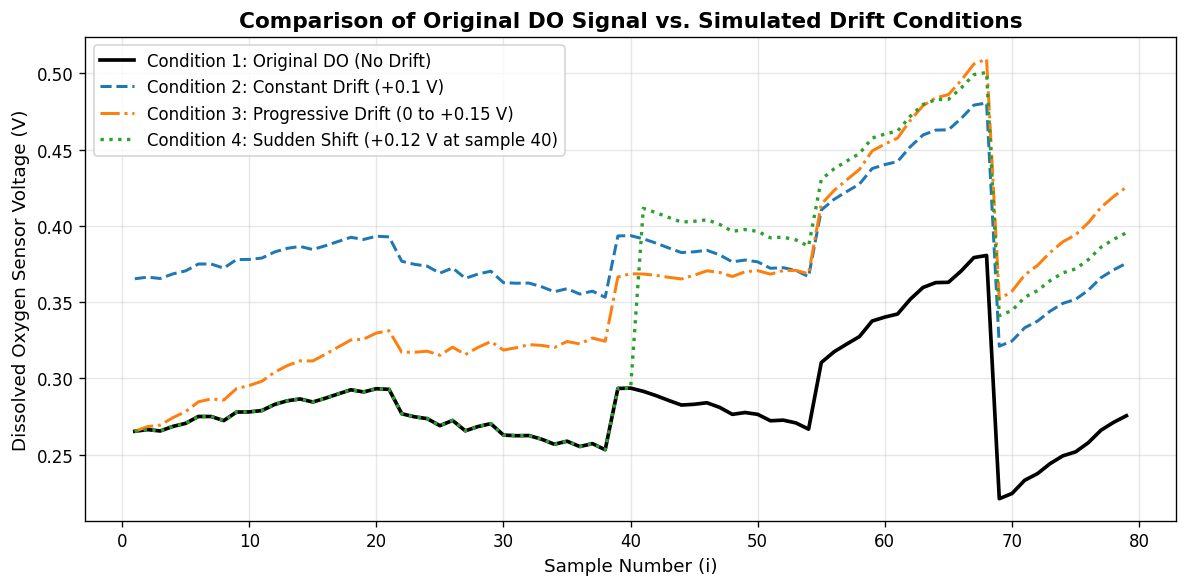

In [3]:
# ==========================================================================
# STUDENT CONTROLS FOR PART 2 (You can test different numbers here if you want!)
# ==========================================================================
CONSTANT_OFFSET  = 0.10   # Condition 2: Constant +0.10 V shift
PROGRESSIVE_MAX  = 0.15   # Condition 3: Gradual increase up to +0.15 V
SUDDEN_SHIFT_VAL = 0.12   # Condition 4: Sudden +0.12 V jump at Sample 40

sample_index = np.arange(len(df_original))  # i = 0 to 78

# Create the 4 DO drift conditions
do_cond1_nodrift     = df_original['DO'].values
do_cond2_constant    = df_original['DO'].values + CONSTANT_OFFSET
do_cond3_progressive = df_original['DO'].values + PROGRESSIVE_MAX * (sample_index / 78.0)
do_cond4_sudden      = df_original['DO'].values + np.where(sample_index >= 40, SUDDEN_SHIFT_VAL, 0.0)

# Plot the Required Figure
plt.figure(figsize=(10, 5), dpi=120)
plt.plot(df_original['Sample_ID'], do_cond1_nodrift, label='Condition 1: Original DO (No Drift)', linewidth=2.2, color='black')
plt.plot(df_original['Sample_ID'], do_cond2_constant, label=f'Condition 2: Constant Drift (+{CONSTANT_OFFSET} V)', linestyle='--', linewidth=1.8)
plt.plot(df_original['Sample_ID'], do_cond3_progressive, label=f'Condition 3: Progressive Drift (0 to +{PROGRESSIVE_MAX} V)', linestyle='-.', linewidth=1.8)
plt.plot(df_original['Sample_ID'], do_cond4_sudden, label=f'Condition 4: Sudden Shift (+{SUDDEN_SHIFT_VAL} V at sample 40)', linestyle=':', linewidth=2.0)

plt.title('Comparison of Original DO Signal vs. Simulated Drift Conditions', fontsize=13, fontweight='bold')
plt.xlabel('Sample Number (i)', fontsize=11)
plt.ylabel('Dissolved Oxygen Sensor Voltage (V)', fontsize=11)
plt.grid(True, alpha=0.3)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

---
## STEP 4 (Part 3 of Assignment): Test Both Models Across All Drift Conditions
**Action:** Click the **Play button (▶)** below. This code tests our clean-trained **Full Model** and **DO-Free Model** on all 4 drift conditions (and automatically updates `TDS / DO_sim` each time!). Copy the printed table into Part 3 of your report.

In [4]:
drift_conditions = {
    'Condition 1: No Drift': do_cond1_nodrift,
    'Condition 2: Constant Drift (+0.10 V)': do_cond2_constant,
    'Condition 3: Progressive Drift': do_cond3_progressive,
    'Condition 4: Sudden Shift': do_cond4_sudden
}

part3_rows = []
for cond_name, do_sim_array in drift_conditions.items():
    # Copy dataset, put in DO_sim, and recalculate TDS / DO_sim
    df_sim = df_original.copy()
    df_sim['DO_sim'] = do_sim_array
    df_sim = add_engineered_features(df_sim, do_col='DO_sim')

    # Test Full Model (Model A)
    acc_f, f1_f, r2_f, rmse_f = evaluate_pipeline(model_A_full, df_sim, do_col_override='DO_sim')
    part3_rows.append({
        'Drift Condition': cond_name,
        'Model': 'Full Model (7-Feature)',
        'Accuracy': acc_f, 'Macro_F1': f1_f, 'R2': r2_f, 'RMSE': rmse_f
    })

    # Test DO-Free Model (Model B)
    acc_d, f1_d, r2_d, rmse_d = evaluate_pipeline(model_B_dofree, df_sim, do_col_override='DO_sim')
    part3_rows.append({
        'Drift Condition': cond_name,
        'Model': 'DO-Free Model (5-Feature)',
        'Accuracy': acc_d, 'Macro_F1': f1_d, 'R2': r2_d, 'RMSE': rmse_d
    })

part3_table = pd.DataFrame(part3_rows)
print('=== PART 3: MODEL STRESS TEST TABLE ===')
print(part3_table.to_string(index=False))

=== PART 3: MODEL STRESS TEST TABLE ===
                      Drift Condition                     Model  Accuracy  Macro_F1      R2   RMSE
                Condition 1: No Drift    Full Model (7-Feature)    1.0000    1.0000  0.9994 0.1521
                Condition 1: No Drift DO-Free Model (5-Feature)    0.9494    0.9501  0.9562 1.2637
Condition 2: Constant Drift (+0.10 V)    Full Model (7-Feature)    0.3291    0.2565 -0.4157 7.1885
Condition 2: Constant Drift (+0.10 V) DO-Free Model (5-Feature)    0.9494    0.9501  0.9562 1.2637
       Condition 3: Progressive Drift    Full Model (7-Feature)    0.5949    0.4558  0.2830 5.1158
       Condition 3: Progressive Drift DO-Free Model (5-Feature)    0.9494    0.9501  0.9562 1.2637
            Condition 4: Sudden Shift    Full Model (7-Feature)    0.6835    0.5501  0.2862 5.1045
            Condition 4: Sudden Shift DO-Free Model (5-Feature)    0.9494    0.9501  0.9562 1.2637


---
## STEP 5 (Part 4 of Assignment): Try ONE Method to Rescue the DO Sensor
**Action:** In the code box below, set `RESCUE_OPTION` to **`1`**, **`2`**, **`3`**, or **`4`**, and click the **Play button (▶)**:
- **`1` = Baseline Correction** (subtracts the initial DO shift from the test session)
- **`2` = Robust Scaling** (uses median/interquartile `RobustScaler` instead of `StandardScaler`)
- **`3` = Alternative Model** (uses a `Random Forest` regressor instead of `SVR`)
- **`4` = Drift Indicator Feature** (adds a sample time-index feature to the model)

In [ ]:
# ==========================================================================
# CHOOSE YOUR RESCUE OPTION HERE (Change the number to 1, 2, 3, or 4)
# ==========================================================================
RESCUE_OPTION = 1   # <--- CHANGE THIS TO 1, 2, 3, OR 4 AND CLICK PLAY!

part4_rows = []
for cond_name, do_sim_array in drift_conditions.items():
    df_sim = df_original.copy()
    df_sim['DO_sim'] = do_sim_array

    if RESCUE_OPTION == 1:
        method_label = 'Option 1: Baseline Zero-Reference Correction'
        # Subtract the starting shift (difference between initial test DO and initial training DO)
        initial_offset = df_sim['DO_sim'].iloc[0] - df_original['DO'].iloc[0]
        df_sim['DO_rescued'] = df_sim['DO_sim'] - initial_offset
        df_sim = add_engineered_features(df_sim, do_col='DO_rescued')
        acc, f1, r2, rmse = evaluate_pipeline(model_A_full, df_sim, do_col_override='DO_rescued')

    elif RESCUE_OPTION == 2:
        method_label = 'Option 2: RobustScaler Normalization'
        df_sim = add_engineered_features(df_sim, do_col='DO_sim')
        model_robust = train_pipeline(df_clean_features, features_full, reg_type='SVR', scaler_type='Robust')
        acc, f1, r2, rmse = evaluate_pipeline(model_robust, df_sim, do_col_override='DO_sim')

    elif RESCUE_OPTION == 3:
        method_label = 'Option 3: Random Forest Regressor'
        df_sim = add_engineered_features(df_sim, do_col='DO_sim')
        model_rf = train_pipeline(df_clean_features, features_full, reg_type='RF', scaler_type='Standard')
        acc, f1, r2, rmse = evaluate_pipeline(model_rf, df_sim, do_col_override='DO_sim')

    elif RESCUE_OPTION == 4:
        method_label = 'Option 4: Drift Time-Index Indicator'
        df_train_idx = df_clean_features.copy()
        df_train_idx['Time_Index'] = np.arange(len(df_train_idx))
        df_sim = add_engineered_features(df_sim, do_col='DO_sim')
        df_sim['Time_Index'] = np.arange(len(df_sim))
        feat_idx = features_full + ['Time_Index']
        model_idx = train_pipeline(df_train_idx, feat_idx, reg_type='SVR', scaler_type='Standard')
        acc, f1, r2, rmse = evaluate_pipeline(model_idx, df_sim, do_col_override='DO_sim')

    part4_rows.append({
        'Drift Condition': cond_name,
        'Rescue Method': method_label,
        'Accuracy': acc, 'Macro_F1': f1, 'R2': r2, 'RMSE': rmse
    })

part4_table = pd.DataFrame(part4_rows)
print(f'=== PART 4 RESULTS FOR {method_label.upper()} ===')
print(part4_table.to_string(index=False))

=== PART 4 RESULTS FOR OPTION 1: BASELINE ZERO-REFERENCE CORRECTION ===
                      Drift Condition                                Rescue Method  Accuracy  Macro_F1     R2   RMSE
                Condition 1: No Drift Option 1: Baseline Zero-Reference Correction    1.0000    1.0000 0.9994 0.1521
Condition 2: Constant Drift (+0.10 V) Option 1: Baseline Zero-Reference Correction    1.0000    1.0000 0.9994 0.1521
       Condition 3: Progressive Drift Option 1: Baseline Zero-Reference Correction    0.5949    0.4558 0.2830 5.1158
            Condition 4: Sudden Shift Option 1: Baseline Zero-Reference Correction    0.6835    0.5501 0.2862 5.1045
